# Sequential sampling of a classification boundary: the UD logo

This notebook applies the three sequential sampling methods from Bhat & Kitchin (2023), *Ind. Eng. Chem. Res.* **62**, 15326–15339 ([doi:10.1021/acs.iecr.3c02362](https://doi.org/10.1021/acs.iecr.3c02362)), to a 2D binary classification problem.

Each "experiment" is a point in the unit square. Its class is 1 if the point lies inside the logo and 0 if it lies outside. A support vector classifier (SVC) is refit after every batch, and the next experiments are chosen from the predicted boundary.

| Method | Where the next experiments go |
|---|---|
| **BIS** (broad initial sampling) | Random boundary points taken from the least-sampled part of the predicted boundary. |
| **LPD** (low point density) | A tight cluster around a centre point. The next centre is the emptiest boundary point, narrowed to the most one-sided class mix, and farthest from earlier samples. |
| **PT** (path tracing) | Steps along the local boundary tangent. Each step samples a pair of points either side of the boundary and adapts the pair spacing. |

The control is a full-factorial grid of n × n points.

## Setup

- **The logo.** The official logo is not in this folder, so the notebook uses a stand-in: the letters "UD" in bold DejaVu Sans. To use your own logo, save it as `ud_logo.png` next to this notebook and set `USE_CUSTOM_LOGO = True`. Opaque, non-white pixels count as logo. Edit the `ink` rule in `logo_mask_from_image` if your logo sits on a white or coloured background.
- **Differences from the paper.** (1) The simulated experiments are exact, with no measurement noise. (2) LPD and PT start from a tight set of samples. That set comes from a 20-point scouting Latin hypercube, then bisection between an inside and an outside point. All scouting and bisection experiments count toward the totals, but the scouting points do not train the model. (3) Convergence uses a simplified rule (every boundary point has at least `min_pts` samples within a radius) plus an experiment budget. (4) The scores are IoU and the mean distance of samples from the true boundary, not the paper's weighted score. (5) The boundary is the SVC decision-function zero rather than the 0.5 contour of Platt probabilities (see Helpers). (6) The RBF width is fixed at `gamma = 50`. sklearn's default `'scale'` gives about 5 for these coordinates and oversmooths the letter outlines.

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.path import Path as MplPath
from matplotlib.textpath import TextPath
from matplotlib.font_manager import FontProperties
from scipy import ndimage
from scipy.spatial import cKDTree
from scipy.spatial.distance import cdist
from scipy.stats import qmc
from sklearn.svm import SVC

HERE = Path.cwd()
FIG_DIR = HERE / "figures"
FIG_DIR.mkdir(exist_ok=True)

SEED = 0
USE_CUSTOM_LOGO = False           # True: load LOGO_PATH instead of the stand-in glyphs
LOGO_PATH = HERE / "ud_logo.png"
TRUTH_RES = 400                   # raster resolution of the true logo (the simulated oracle)
GRID_RES = 150                    # evaluation grid used to draw and score the predicted boundary
N_SEEDS = 5                       # repeats of each stochastic sequential method
BUDGET = 350                      # maximum experiments per sequential run
GRID_SIDES = [4, 6, 8, 10, 12, 14, 16, 18]   # full-factorial controls: n*n experiments each
C_SVM = 10.0                      # SVC regularisation
SVC_GAMMA = 50.0                  # RBF width; sklearn's 'scale' (about 5 here) oversmooths the letter outlines

plt.rcParams.update({"font.size": 10, "axes.linewidth": 0.8, "figure.dpi": 120})


def save_fig(fig, name):
    """Save PNG and PDF at 600 dpi, cropped to content."""
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"{name}.{ext}", dpi=600, bbox_inches="tight")

## The ground truth

The oracle returns 1 inside the logo and 0 outside. The sequential methods only see the oracle's answers, never the mask itself. The mask is used only to score each model.

True logo covers 19.4% of the unit square


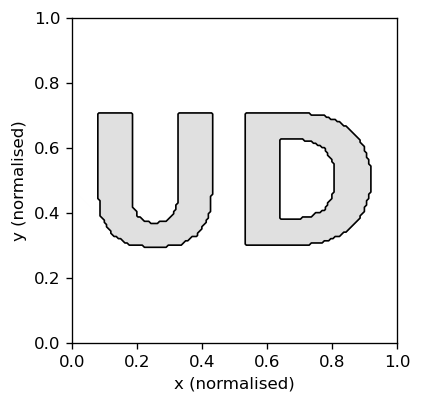

In [2]:
def standin_logo_mask(res=TRUTH_RES, margin=0.08):
    """Bold 'UD' glyphs scaled into the unit square. mask[iy, ix] is True inside the logo (row 0 = y = 0)."""
    tp = TextPath((0, 0), "UD", size=1.0, prop=FontProperties(family="DejaVu Sans", weight="bold"))
    ext = tp.get_extents()
    scale = (1 - 2 * margin) / max(ext.width, ext.height)
    w, h = ext.width * scale, ext.height * scale
    verts = (tp.vertices - [ext.x0, ext.y0]) * scale + [0.5 - w / 2, 0.5 - h / 2]
    # Even-odd fill, so the counter of the D stays empty: test each contour on its own and XOR the results.
    g = (np.arange(res) + 0.5) / res
    gx, gy = np.meshgrid(g, g)
    pts = np.column_stack([gx.ravel(), gy.ravel()])
    codes = tp.codes
    starts = np.flatnonzero(codes == MplPath.MOVETO)
    ends = np.append(starts[1:], len(codes))
    inside = np.zeros(len(pts), dtype=bool)
    for s, e in zip(starts, ends):
        inside ^= MplPath(verts[s:e], codes[s:e]).contains_points(pts)
    return inside.reshape(res, res)


def logo_mask_from_image(path, res=TRUTH_RES):
    """Binary logo mask from an image: opaque, non-white pixels count as logo. Cropped and scaled to a square."""
    from PIL import Image
    rgba = np.asarray(Image.open(path).convert("RGBA")).astype(float) / 255
    ink = (rgba[..., 3] > 0.5) & (rgba[..., :3].mean(axis=-1) < 0.85)   # edit this rule if needed
    ys, xs = np.nonzero(ink)
    ink = ink[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    side = max(ink.shape)
    square = np.zeros((side, side), dtype=np.uint8)
    r0, c0 = (side - ink.shape[0]) // 2, (side - ink.shape[1]) // 2
    square[r0:r0 + ink.shape[0], c0:c0 + ink.shape[1]] = ink
    big = Image.fromarray(square * 255).resize((res, res), Image.BILINEAR)
    return (np.asarray(big) > 127)[::-1]          # image row 0 is the top; flip so y increases upward


TRUTH = logo_mask_from_image(LOGO_PATH) if USE_CUSTOM_LOGO else standin_logo_mask()


class LogoOracle:
    """Simulated experiment: 1 if the point is inside the logo, 0 otherwise."""

    def __init__(self, mask):
        self.mask, self.n = mask, mask.shape[0]

    def __call__(self, X):
        X = np.clip(np.atleast_2d(X), 0, 1 - 1e-9)
        ix = (X[:, 0] * self.n).astype(int)
        iy = (X[:, 1] * self.n).astype(int)
        return self.mask[iy, ix].astype(int)


oracle = LogoOracle(TRUTH)

G = (np.arange(GRID_RES) + 0.5) / GRID_RES     # 1-D cell centres
GX, GY = np.meshgrid(G, G)                     # arrays indexed [iy, ix]
EVAL_XY = np.column_stack([GX.ravel(), GY.ravel()])
TRUE_REGION = oracle(EVAL_XY).reshape(GRID_RES, GRID_RES).astype(bool)
print(f"True logo covers {TRUE_REGION.mean():.1%} of the unit square")

fig, ax = plt.subplots(figsize=(3.6, 3.6))
ax.contourf(GX, GY, TRUE_REGION.astype(float), levels=[0.5, 1.5], colors=["0.88"])
ax.contour(GX, GY, TRUE_REGION.astype(float), levels=[0.5], colors="k", linewidths=1.0)
ax.set_aspect("equal")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("x (normalised)")
ax.set_ylabel("y (normalised)")
fig.tight_layout()
save_fig(fig, "true_logo")
plt.show()

## Helpers

The model is an RBF support vector classifier. The predicted boundary is the zero level set of its decision function, which is the edge of the region `f >= 0`. The paper uses the 0.5 contour of Platt-scaled probabilities. With only 20 to 40 samples those probabilities stay below 0.5 almost everywhere, so the paper's contour cannot be used in the early iterations.

In [3]:
def edge_of(region):
    """Pixels inside a region that touch its complement: the boundary, one pixel thick."""
    return region & ~ndimage.binary_erosion(region)


def edge_points(region):
    iy, ix = np.nonzero(edge_of(region))
    return np.column_stack([G[ix], G[iy]])


TRUE_EDGE_XY = EVAL_XY[edge_of(TRUE_REGION).ravel()]
TRUE_TREE = cKDTree(TRUE_EDGE_XY)


def iou(region):
    return np.logical_and(region, TRUE_REGION).sum() / np.logical_or(region, TRUE_REGION).sum()


def fit_svc(X, y):
    """RBF support vector classifier."""
    if len(np.unique(y)) < 2:
        return None
    return SVC(kernel="rbf", C=C_SVM, gamma=SVC_GAMMA).fit(X, y)


def decision_grid(clf):
    """Signed SVC decision value on the evaluation grid. The predicted boundary is its zero level set."""
    if clf is None:
        return np.full((GRID_RES, GRID_RES), -1.0)
    return clf.decision_function(EVAL_XY).reshape(GRID_RES, GRID_RES)


def predicted_region(clf):
    """Boolean region predicted to be inside the logo."""
    return decision_grid(clf) >= 0


def lhs(n, rng):
    return qmc.LatinHypercube(d=2, seed=int(rng.integers(2**31))).random(n)


def jitter(P, rng):
    """Move points off the evaluation lattice by up to half a grid cell."""
    return np.clip(P + rng.uniform(-0.5 / GRID_RES, 0.5 / GRID_RES, P.shape), 0, 1)


def sample_disk(centre, radius, n, rng):
    r = radius * np.sqrt(rng.uniform(size=n))
    th = rng.uniform(0, 2 * np.pi, n)
    return np.clip(centre + np.column_stack([r * np.cos(th), r * np.sin(th)]), 0, 1)


def initial_design(n0, rng):
    """Latin hypercube start, enlarged until both classes are present (BIS needs both)."""
    while True:
        X = lhs(n0, rng)
        y = oracle(X)
        if 0 < y.sum() < len(y):
            return X, y
        n0 += 5


def tight_start(rng, n_scout=20, n_bisect=9):
    """LPD/PT start: a scouting LHS finds an inside/outside pair, then bisection between them finds a boundary point.
    Scouting and bisection experiments are counted; only the pair and bisection points train the model."""
    S, sy = initial_design(n_scout, rng)
    ins, outs = S[sy == 1], S[sy == 0]
    i, j = np.unravel_index(cdist(ins, outs).argmin(), (len(ins), len(outs)))
    a, b = ins[i].copy(), outs[j].copy()
    X, y = [a, b], [1, 0]
    for _ in range(n_bisect):
        m = 0.5 * (a + b)
        lab = int(oracle(m[None])[0])
        X.append(m)
        y.append(lab)
        if lab == 1:
            a = m
        else:
            b = m
    return np.array(X), np.array(y), 0.5 * (a + b), len(S) + n_bisect

## Method 1: BIS (broad initial sampling)

1. Latin hypercube start, then classify.
2. Fit the SVC and take the predicted boundary.
3. Count the samples within radius `r` of each boundary point.
4. Keep the boundary points with the lowest count. Draw `n_batch` of them at random.
5. Stop when every boundary point has at least `min_pts` samples within `r`, or when the budget runs out.

The stopping rule only sees the boundary the model has already found. If the initial design misses a whole part of the logo, BIS stops with that part undiscovered. With a 20-point start, 2 of 5 seeds stopped at IoU ~0.41 without ever sampling the D. The default start is therefore 40 points. With that start, all five seeds sample both letters, though they differ in how completely they trace the D and how many stray points they leave outside the logo.

In [4]:
def run_bis(rng, n0=40, n_batch=8, radius=0.05, min_pts=3, max_iter=60):
    X, y = initial_design(n0, rng)
    hist = {"method": "BIS", "n": [], "iou": []}
    while True:
        clf = fit_svc(X, y)
        region = predicted_region(clf)
        hist["n"].append(len(X))
        hist["iou"].append(iou(region))
        B = edge_points(region)
        if len(X) >= BUDGET or len(hist["n"]) > max_iter or len(B) == 0:
            break
        counts = cKDTree(X).query_ball_point(B, radius, return_length=True)
        if counts.min() >= min_pts:                       # convergence: boundary is well sampled
            break
        cand = B[counts == counts.min()]                  # least-sampled boundary points
        pick = cand[rng.choice(len(cand), size=min(n_batch, len(cand)), replace=False)]
        pick = jitter(pick, rng)
        X = np.vstack([X, pick])
        y = np.concatenate([y, oracle(pick)])
    hist.update(X=X, y=y, region=region, clf=clf)
    return hist

## Method 2: LPD (low point density)

1. Sample a tight cluster around the current centre, then refit the SVC.
2. Take the predicted boundary inside a box around the samples, expanded by `delta`.
3. Compute the sample density within radius `r1` at each boundary point. Keep the emptiest points.
4. If several remain, keep those whose radius-`r2` neighbourhood is most one-sided (largest |n1 - n0|).
5. The next centre is the remaining point farthest from the existing samples on average.
6. Stop when the box covers the whole domain and every boundary point is well sampled, or when the budget runs out.

In [5]:
def run_lpd(rng, n_batch=8, sample_radius=0.03, r1=0.04, r2=0.08, delta=0.05, min_pts=3, max_iter=80):
    X, y, _, spent = tight_start(rng)
    hist = {"method": "LPD", "n": [], "iou": []}
    while True:
        clf = fit_svc(X, y)
        region = predicted_region(clf)
        hist["n"].append(spent)
        hist["iou"].append(iou(region))
        if spent >= BUDGET or len(hist["n"]) > max_iter:
            break
        lo = np.clip(X.min(axis=0) - delta, 0, 1)      # bounding box of samples, expanded by delta
        hi = np.clip(X.max(axis=0) + delta, 0, 1)
        B = edge_points(region)
        B = B[np.all((B >= lo) & (B <= hi), axis=1)]
        if len(B) == 0:
            break
        tree = cKDTree(X)
        counts = tree.query_ball_point(B, r1, return_length=True)
        if np.all(lo == 0) and np.all(hi == 1) and counts.min() >= min_pts:
            break
        cand = B[counts == counts.min()]               # emptiest boundary points
        if len(cand) > 1:                              # keep the most one-sided class mixes
            nbrs = tree.query_ball_point(cand, r2)
            imbalance = np.array([abs(2 * y[idx].sum() - len(idx)) for idx in nbrs])
            cand = cand[imbalance == imbalance.max()]
        centre = cand[cdist(cand, X).mean(axis=1).argmax()]    # farthest from prior samples
        pts = sample_disk(centre, sample_radius, n_batch, rng)
        X = np.vstack([X, pts])
        y = np.concatenate([y, oracle(pts)])
        spent += len(pts)
    hist.update(X=X, y=y, region=region, clf=clf)
    return hist

## Method 3: PT (path tracing)

1. Take the boundary point nearest the current centre and estimate the local tangent from nearby boundary points.
2. Step a distance `step` along the tangent to a new centre.
3. Sample two points at offsets `d` on either side of the new centre, perpendicular to the tangent.
4. If the two points differ in class, accept the new centre and shrink `d`. If not, keep the old centre and grow `d`.
5. Stop when the path returns to its start, or when the budget runs out.

PT follows one closed boundary loop from its start point. It does not find other loops, so on a logo with several letters it covers only part of the boundary.

In [6]:
def run_pt(rng, step=0.03, d0=0.02, d_min=0.004, d_max=0.12, max_iter=300):
    X, y, centre, spent = tight_start(rng)
    start, d, prev_t, n_steps = centre.copy(), d0, None, 0
    hist = {"method": "PT", "n": [], "iou": []}
    while True:
        clf = fit_svc(X, y)
        region = predicted_region(clf)
        hist["n"].append(spent)
        hist["iou"].append(iou(region))
        B = edge_points(region)
        if spent >= BUDGET or len(hist["n"]) > max_iter or len(B) == 0:
            break
        if n_steps > 10 and np.linalg.norm(centre - start) < 1.5 * step:   # loop closed
            break
        b = B[np.linalg.norm(B - centre, axis=1).argmin()]                 # boundary point nearest the centre
        patch = B[np.linalg.norm(B - b, axis=1) < 1.5 * step]
        t = np.linalg.svd(patch - patch.mean(axis=0))[2][0]                # local tangent direction
        if prev_t is not None and t @ prev_t < 0:
            t = -t
        prev_t = t
        normal = np.array([-t[1], t[0]])
        new_centre = np.clip(b + step * t, 0, 1)
        pair = np.clip(np.vstack([new_centre + d * normal, new_centre - d * normal]), 0, 1)
        lab = oracle(pair)
        X = np.vstack([X, pair])
        y = np.concatenate([y, lab])
        spent += 2
        if lab[0] != lab[1]:             # boundary lies between the pair: accept the step, tighten the pair
            centre = new_centre
            d = max(0.7 * d, d_min)
            n_steps += 1
        else:                            # not bracketed: keep the centre and sample farther out
            d = min(1.5 * d, d_max)
    hist.update(X=X, y=y, region=region, clf=clf)
    return hist

## Control: full-factorial grid

An n × n grid over the unit square, with the same SVC. Each control run uses n² experiments.

In [7]:
def run_grid(n_side):
    s = np.linspace(0, 1, n_side)
    gx, gy = np.meshgrid(s, s)
    X = np.column_stack([gx.ravel(), gy.ravel()])
    y = oracle(X)
    clf = fit_svc(X, y)
    region = predicted_region(clf)
    return {"method": "Grid", "n": len(X), "iou": iou(region), "region": region, "clf": clf, "X": X, "y": y}

## Run everything

Each sequential method runs `N_SEEDS` times with different random seeds. The table reports medians across seeds, as in the paper. Expect a few minutes of run time.

In [8]:
t0 = time.time()
runners = {"BIS": run_bis, "LPD": run_lpd, "PT": run_pt}
RUNS = {name: [fn(np.random.default_rng(SEED + s)) for s in range(N_SEEDS)] for name, fn in runners.items()}
GRID_RUNS = [run_grid(k) for k in GRID_SIDES]
print(f"Finished in {time.time() - t0:.1f} s")


def summarise(runs):
    return {
        "experiments": np.median([r["n"][-1] for r in runs]),
        "IoU": np.median([r["iou"][-1] for r in runs]),
        "mean distance of samples to true boundary": np.median([TRUE_TREE.query(r["X"])[0].mean() for r in runs]),
    }


summary = pd.DataFrame.from_dict({name: summarise(runs) for name, runs in RUNS.items()}, orient="index")
grid_summary = pd.DataFrame.from_dict(
    {f"Grid {k}x{k}": {"experiments": r["n"], "IoU": r["iou"],
                       "mean distance of samples to true boundary": TRUE_TREE.query(r["X"])[0].mean()}
     for k, r in zip(GRID_SIDES, GRID_RUNS)},
    orient="index",
)
pd.concat([summary, grid_summary]).round(3)

per_seed = pd.DataFrame(
    {name: [round(r["iou"][-1], 3) for r in runs] for name, runs in RUNS.items()},
    index=[f"seed {SEED + s}" for s in range(N_SEEDS)],
)
per_seed

Finished in 24.3 s


,BIS,LPD,PT
seed 0,0.824,0.432,0.426
seed 1,0.834,0.432,0.424
seed 2,0.754,0.428,0.440
seed 3,0.680,0.439,0.434
seed 4,0.847,0.201,0.199


## Learning curves

IoU against experiments used. Each sequential curve is the median over seeds of the most recent model fitted within the experiment budget. The grid points are the full-factorial controls.

/var/folders/f9/38nkw6517lgf362dv55hy0xc0000gn/T/ipykernel_39030/2852532952.py:11: RuntimeWarning: All-NaN slice encountered
  curves = {name: np.nanmedian(np.array([iou_at(r, N_COMMON) for r in runs]), axis=0)


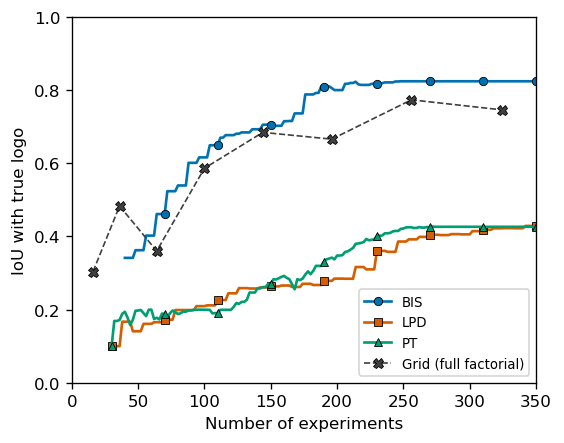

In [9]:
N_COMMON = np.arange(30, BUDGET + 1, 2)     # every run has at least 29 experiments


def iou_at(run, N):
    """IoU of the most recent model fitted with at most N experiments (step interpolation)."""
    n_arr, iou_arr = np.asarray(run["n"]), np.asarray(run["iou"])
    idx = np.searchsorted(n_arr, N, side="right") - 1
    return np.where(idx >= 0, iou_arr[np.clip(idx, 0, None)], np.nan)


curves = {name: np.nanmedian(np.array([iou_at(r, N_COMMON) for r in runs]), axis=0)
          for name, runs in RUNS.items()}

COLORS = {"BIS": "#0072B2", "LPD": "#D55E00", "PT": "#009E73", "Grid": "0.25"}
MARKERS = {"BIS": "o", "LPD": "s", "PT": "^"}

fig, ax = plt.subplots(figsize=(4.8, 3.8))
for name in ["BIS", "LPD", "PT"]:
    ax.plot(N_COMMON, curves[name], color=COLORS[name], lw=1.6, marker=MARKERS[name],
            markevery=20, ms=5, mec="k", mew=0.5, label=name)
ax.plot([r["n"] for r in GRID_RUNS], [r["iou"] for r in GRID_RUNS], color=COLORS["Grid"], ls="--", lw=1.0,
        marker="X", ms=6, mec="k", mew=0.5, label="Grid (full factorial)")
ax.set_xlim(0, BUDGET)
ax.set_ylim(0, 1)
ax.set_xlabel("Number of experiments")
ax.set_ylabel("IoU with true logo")
ax.legend(loc="lower right", frameon=True, fontsize=8)
fig.tight_layout()
save_fig(fig, "iou_vs_experiments")
plt.show()

## Final boundaries

Seed 0 of each method. The grey region is the true logo, and the dashed outline is its edge. The solid black line is the predicted boundary (zero decision value). Blue points are outside the logo and gold points are inside.

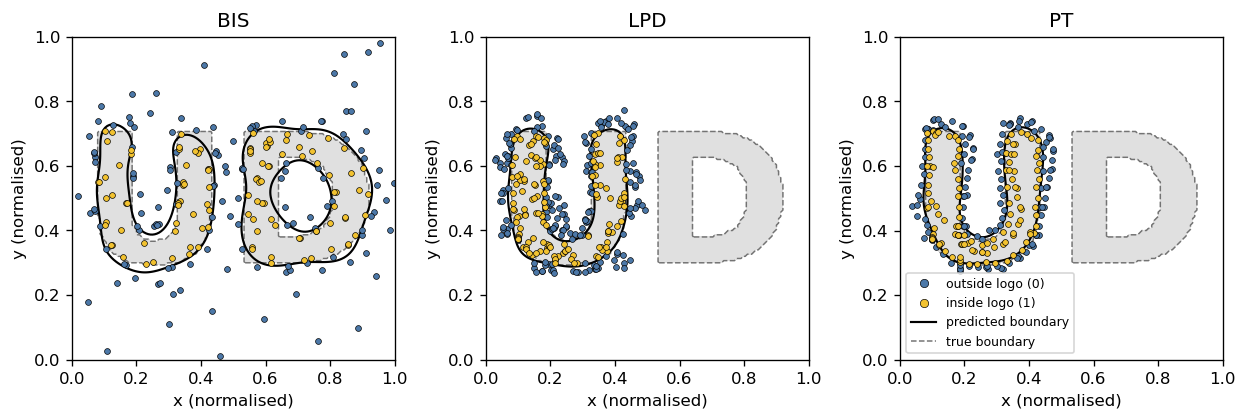

In [10]:
def plot_snapshot(ax, run):
    f = decision_grid(run["clf"])
    ax.contourf(GX, GY, TRUE_REGION.astype(float), levels=[0.5, 1.5], colors=["0.88"])
    ax.contour(GX, GY, TRUE_REGION.astype(float), levels=[0.5], colors=["0.45"], linestyles="--", linewidths=0.9)
    ax.contour(GX, GY, f, levels=[0.0], colors="k", linewidths=1.3)
    X, y = run["X"], run["y"]
    ax.plot(X[y == 0, 0], X[y == 0, 1], "o", ms=3.5, mfc="#4C78A8", mec="k", mew=0.4, ls="none")
    ax.plot(X[y == 1, 0], X[y == 1, 1], "o", ms=3.5, mfc="#F2C230", mec="k", mew=0.4, ls="none")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect("equal")
    ax.set_xlabel("x (normalised)")
    ax.set_ylabel("y (normalised)")
    ax.set_title(run["method"])


fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.7))
for ax, name in zip(axes, ["BIS", "LPD", "PT"]):
    plot_snapshot(ax, RUNS[name][0])
handles = [
    Line2D([], [], marker="o", ls="none", mfc="#4C78A8", mec="k", mew=0.4, ms=5, label="outside logo (0)"),
    Line2D([], [], marker="o", ls="none", mfc="#F2C230", mec="k", mew=0.4, ms=5, label="inside logo (1)"),
    Line2D([], [], color="k", lw=1.3, label="predicted boundary"),
    Line2D([], [], color="0.45", ls="--", lw=0.9, label="true boundary"),
]
axes[-1].legend(handles=handles, loc="lower left", frameon=True, fontsize=7.5)
fig.tight_layout()
save_fig(fig, "method_snapshots")
plt.show()

## BIS against a grid at a similar budget

Seed 0 of BIS, next to the largest full-factorial grid that uses no more experiments than that BIS run. Both show the same logo, so the panels compare how each method spends its experiments.

BIS: 248 experiments, IoU 0.824
Grid: 196 experiments, IoU 0.666


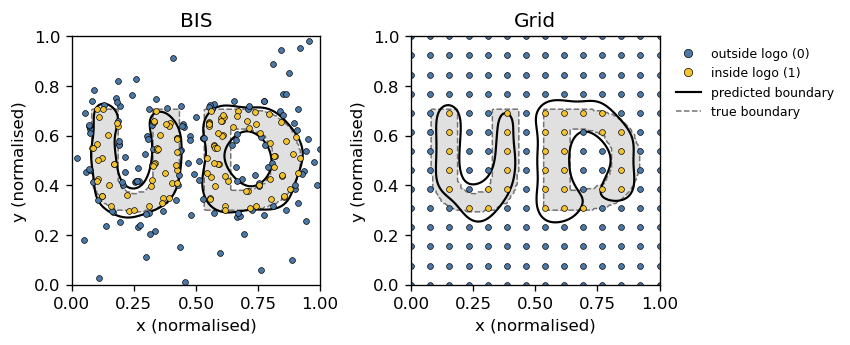

In [11]:
bis_run = RUNS["BIS"][0]
matched = max((g for g in GRID_RUNS if g["n"] <= bis_run["n"][-1]), key=lambda g: g["n"])
print(f"BIS: {bis_run['n'][-1]} experiments, IoU {bis_run['iou'][-1]:.3f}")
print(f"Grid: {matched['n']} experiments, IoU {matched['iou']:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.7))
plot_snapshot(axes[0], bis_run)
plot_snapshot(axes[1], matched)
axes[1].legend(handles=handles, loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False, fontsize=7.5)
fig.tight_layout()
save_fig(fig, "bis_vs_grid")
plt.show()